<a href="https://colab.research.google.com/github/DiegoCoAnz/steam-price-prediction-ml/blob/main/ML_CocaDiego.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Autor y Metadatos del Proyecto

* **Autor:** Diego Coca
* **Formación Académica:** Ingeniero en Electrónica
* **Correo Electrónico:** dcoca28@gmail.com
* **LinkedIn:** [linkedin.com/in/coca-diego](https://linkedin.com/in/coca-diego)
* **GitHub:** [Tu Usuario de GitHub](https://github.com/DiegoCoAnz)

---
*Proyecto Integrador / Pre-Entrega - Machine Learning e Inteligencia Artificial*

# Cuaderno Pre-Entrega Lab

En este cuaderno vamos a trabajar sobre las etapas necesarias para preparar la Pre-Entrega del Proyecto Integrador del curso de Machine Learning.

La idea principal de este taller no es entrenar todavía un modelo, sino dejar preparado un dataset para poder hacerlo más adelante. Para eso vamos a recorrer las etapas previas al modelado: selección del dataset, análisis inicial, limpieza, transformaciones básicas, selección de variables y división del conjunto de datos.

A lo largo del cuaderno vamos a trabajar con un dataset de ejemplo, pero muchas de las decisiones que tomemos podrán adaptarse a otros datasets. Por eso, además de resolver el caso propuesto, iremos explicando qué conviene observar y justificar en cada etapa.

Cabe aclarar que esta pre-entrega puede ser modificada tanto en proposito como el dataset por los motivos a un mejor analisis.

In [ ]:


#Procedo a habilitar la importacion de archivos de GoogleDrive a Collab
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Justificación de la Selección del Dataset: Steam Games
El dataset se presenta en un formato estrictamente tabular, compuesto por filas que representan registros individuales de videojuegos y columnas que describen sus atributos técnicos y comerciales. Su escala permite un procesamiento eficiente en entornos de desarrollo en la nube sin comprometer los recursos computacionales.
# 2. Definición de la Variable Objetivo (Target)
El conjunto de datos habilita la formulación de un problema predictivo claro. Como variable objetivo se establece el campo correspondiente al precio del producto (Price), lo cual enmarca el proyecto dentro de un problema de regresión. El propósito analítico consistirá en estimar el valor numérico del precio en función de variables predictoras asociadas a las características del software (tales como género, año de lanzamiento, métricas de recepción y especificaciones técnicas).
# 3. Diversidad de Tipos de Datos
El dataset incluye una combinación equilibrada de variables cuantitativas (como métricas de uso y precios) y cualitativas (como categorías, desarrolladores y plataformas). Esta heterogeneidad es fundamental para aplicar técnicas de preprocesamiento, codificación de variables categóricas y análisis de correlación durante las etapas posteriores del pipeline de Machine Learning.
# 4. Relevancia y Explicabilidad
La industria del videojuego ofrece un caso de estudio de alta relevancia económica y analítica. La naturaleza de las variables permite un entendimiento intuitivo del dominio del problema, facilitando la justificación de las decisiones metodológicas tomadas en las fases de limpieza, selección de características y validación del modelo.


In [ ]:
# Instalamos (no se ha utilizado) kagglehub para poder descargar
# datasets desde Kaggle. Normalmente, Colab lo tiene incorporado.
# !pip install kagglehub -q

# Librerías para manipulación de datos
import pandas as pd
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para descargar y ubicar archivos
import kagglehub
import os

#Para poder usar el DataSet desde drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print("Archivos subidos en tu Colab:\n")
print(os.listdir())

Archivos subidos en tu Colab:

['.config', 'drive', 'sample_data']


In [ ]:
# Configuración básica para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Carga del dataset en un DataFrame
El archivo principal del dataset se llama games_march2025_full.cvs

proveniente de la siguiente pagina
https://www.kaggle.com/datasets/artermiloff/steam-games-dataset?select=games_march2025_full.csv

Vamos a cargarlo en un DataFrame de pandas llamado df. A partir de este momento, df será la tabla principal con la que trabajaremos durante el cuaderno.

Luego mostraremos las primeras filas para tener una primera idea de cómo están organizados los datos.

In [ ]:
# Cargar el dataset
df = pd.read_csv('/content/drive/MyDrive/ML_PRE-ENTREGA/games_march2025_full.csv')
# Ahora imprimís tu tabla normal
df.head()


,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,...,771,7101,74,0,117698,"{'Open World': 32644, 'Action': 23539, 'Multip...",87,1803832,92,17517
4,488824,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,19.99,9,Edition Comparison Ultimate Edition The Tom Cl...,“One of the best first-person shooters ever ma...,"Tom Clancy's Rainbow Six® Siege is an elite, t...",NaN,...,0,0,0,0,0,"{'FPS': 8082, 'Multiplayer': 6139, 'Tactical':...",84,1168404,76,13017


## Diagnóstico inicial del dataset

Antes de limpiar o transformar los datos, necesitamos conocer la estructura general del dataset.

En esta etapa vamos a revisar:

- cuántas filas y columnas tiene;
- qué columnas están disponibles;
- qué tipo de dato tiene cada columna;
- si existen valores faltantes.

Este diagnóstico inicial nos ayudará a tomar decisiones en las próximas etapas del cuaderno.

In [ ]:
# Mostramos las dimensiones del dataset
# Impresión formal de las dimensiones del dataset
print("Dimensiones del dataset:")
print(f" - Total de registros (filas): {df.shape[0]:,}")
print(f" - Total de variables (columnas): {df.shape[1]}")

# Mostramos los nombres de las columnas
# Mostramos los nombres de las columnas organizados en filas de 10 elementos
print("\nColumnas disponibles:")
columnas = df.columns.tolist()
tamanio_grupo = 10

for i in range(0, len(columnas), tamanio_grupo):
    grupo = columnas[i:i + tamanio_grupo]
    print(" | ".join(grupo))

# Mostramos los tipos de datos de cada columna
print("\nTipos de datos:")
print(df.dtypes)

# Revisamos la cantidad de valores faltantes por columna
print("\nValores faltantes por columna:")
print(df.isnull().sum())

Dimensiones del dataset:
 - Total de registros (filas): 94,948
 - Total de variables (columnas): 47

Columnas disponibles:
appid | name | release_date | required_age | price | dlc_count | detailed_description | about_the_game | short_description | reviews
header_image | website | support_url | support_email | windows | mac | linux | metacritic_score | metacritic_url | achievements
recommendations | notes | supported_languages | full_audio_languages | packages | developers | publishers | categories | genres | screenshots
movies | user_score | score_rank | positive | negative | estimated_owners | average_playtime_forever | average_playtime_2weeks | median_playtime_forever | median_playtime_2weeks
discount | peak_ccu | tags | pct_pos_total | num_reviews_total | pct_pos_recent | num_reviews_recent

Tipos de datos:
appid                         int64
name                         object
release_date                 object
required_age                  int64
price                       float6

Tras realizar el análisis de valores nulos mediante el método `isnull()`  `.sum()`, se observa que las variables principales de estudio tales como el precio (`price`), la fecha de lanzamiento (`release_date`) y los desarrolladores (`developers`) presentan un total de cero (0) valores faltantes.

Esto garantiza la consistencia estructural de los datos para estas dimensiones. No obstante, se identifican columnas con alta proporción de nulos (como reseñas externas o puntajes de crítica especializada), las cuales corresponden a características opcionales o no aplicables a todo el catálogo de videojuegos, aspecto que deberá gestionarse mediante la exclusión de dichas variables en la selección de características (feature selection) si su impacto analítico no es concluyente.

#Revisión de valores faltantes
El diagnóstico inicial muestra que todas las columnas tienen 3 valores faltantes.

Cuando ocurre esto, es posible que los valores faltantes estén concentrados en algunas filas completas, en lugar de estar distribuidos por todo el dataset.

Por eso, antes de decidir qué hacer, vamos a mostrar las filas que contienen al menos un valor faltante.

In [ ]:
# Mostramos las filas que tienen al menos un valor faltante
filas_con_nulos = df[df.isnull().any(axis=1)]

filas_con_nulos

,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,...,771,7101,74,0,117698,"{'Open World': 32644, 'Action': 23539, 'Multip...",87,1803832,92,17517
4,488824,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,19.99,9,Edition Comparison Ultimate Edition The Tom Cl...,“One of the best first-person shooters ever ma...,"Tom Clancy's Rainbow Six® Siege is an elite, t...",NaN,...,0,0,0,0,0,"{'FPS': 8082, 'Multiplayer': 6139, 'Tactical':...",84,1168404,76,13017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94943,2115110,Outrun Them,2024-02-29,0,3.99,0,The name of the game is literally the game. Ou...,The name of the game is literally the game. Ou...,It's all in the name.. outrun them.,NaN,...,0,0,0,0,0,"{'2D Platformer': 91, 'Runner': 85, 'Platforme...",-1,-1,-1,-1
94944,1174200,Lands of Pharaoh: Episode 1,2020-01-07,0,10.00,0,Join Our Discord Channel About the Game Briefl...,Briefly: Lands of Pharaoh is a third person vi...,Lands of Pharaoh is a multi-camera-angle based...,NaN,...,0,0,0,0,0,"{'Action': 43, 'Adventure': 41, 'Indie': 41, '...",-1,-1,-1,-1
94945,1160190,Player One,2019-10-10,0,1.99,0,Player One is a new 3D game where you take con...,Player One is a new 3D game where you take con...,"3D Game, Thirdperson Platformer",NaN,...,0,0,0,0,0,"{'Indie': 31, 'Early Access': 21}",-1,-1,-1,-1
94946,3380340,DragonRoad,2025-01-25,0,29.99,0,"This is an open world game on 3D, also a m...","This is an open world game on 3D, also a m...","This is an open world game on 3D, Also a missi...",NaN,...,0,0,0,0,0,"{'RPG': 117, 'Action-Adventure': 111, 'Strateg...",-1,-1,-1,-1


Tras aplicar un filtro sobre el conjunto de datos para aislar los registros con valores faltantes `(isnull().any(axis=1))`, se obtuvo una dimensión de 94,948 filas afectadas.

Este diagnóstico evidencia que la presencia de datos nulos es transversal a todo el catálogo, afectando incluso a videojuegos de alta capitalización de mercado.

#Resultado de la revisión de duplicados
El dataset no contiene filas duplicadas.

Por lo tanto, no es necesario eliminar registros en esta etapa. Continuaremos trabajando con las 94,948 filas disponibles.

### Criterios y Metodología para la Reducción y Filtrado del Dataset

En las etapas iniciales de preparación de un proyecto de Machine Learning, uno de los desafíos más comunes es lidiar con datasets masivos que contienen decenas de columnas (en este caso, más de 40 variables originales). Trabajar con la totalidad de estas dimensiones resulta ineficiente y, en muchos casos, contraproducente para los algoritmos predictivos. Por lo tanto, se aplicó una estrategia de reducción y filtrado basada en los siguientes ejes metodológicos:

#### 1. Descarte de Variables Irrelevantes o Redundantes
Gran parte de las columnas originales de un dataset de esta naturaleza corresponden a elementos no estructurados (como descripciones textuales masivas, rutas de imágenes, URLs de sitios web externos o metadatos de soporte) que no aportan información cuantitativa ni categórica útil para un modelo matemático. El primer paso consistió en excluir estas dimensiones para evitar la sobrecarga de datos y el ruido analítico.

#### 2. Selección Basada en el Objetivo Analítico (*Feature Selection*)
El proceso de reducción se estructuró en torno a nuestra variable objetivo (*target*), definida como el precio del videojuego (`price`). Bajo este criterio, se retuvieron únicamente aquellas variables que poseen un fundamento lógico y comercial en la estimación del valor de mercado de un producto software, tales como:
* Atributos temporales y de antigüedad (`release_date`).
* Características estructurales y de escala (`developers`, `publishers`, `genres`).
* Restricciones y especificaciones técnicas (`required_age`, soporte multiplataforma como `windows`, `mac`, `linux`).
* Indicadores comerciales y de recepción (`estimated_owners`, `dlc_count`, `achievements`).

#### 3. Optimización del Volumen de Datos
Mediante esta selección estricta, el DataFrame original se transformó en un subconjunto optimizado de trabajo (`df_modelo`). Esta reducción dimensional no solo simplifica las operaciones computacionales subsiguientes, sino que garantiza que cada columna retenida cumpla un rol explícito en el proceso de entrenamiento del futuro modelo predictivo, preservando la calidad e integridad de los datos.

In [ ]:
# Selección optimizada de variables predictoras incluyendo publishers, soporte multiplataforma y metacritic_score
columnas_relevantes = [
    'name',              # Identificador descriptivo
    'release_date',      # Temporalidad y antigüedad
    'required_age',      # Restricción de edad
    'developers',        # Estudio desarrollador
    'publishers',        # Empresa editora
    'genres',            # Género del software
    'dlc_count',         # Cantidad de contenidos descargables
    'estimated_owners',  # Magnitud de la base de usuarios
    'achievements',      # Complejidad y cantidad de logros
    'windows',           # Soporte para Windows
    'mac',               # Soporte para Mac
    'linux',             # Soporte para Linux
    'metacritic_score',  # Puntuación de la crítica especializada
    'price'              # Variable objetivo (Target)
]

# Creamos df_modelo a partir de df usando las columnas seleccionadas para evitar el NameError
df_modelo = df[columnas_relevantes].copy()
df_modelo.head()

,name,release_date,required_age,developers,publishers,genres,dlc_count,estimated_owners,achievements,windows,mac,linux,metacritic_score,price
0,Counter-Strike 2,2012-08-21,0,['Valve'],['Valve'],"['Action', 'Free To Play']",1,100000000 - 200000000,1,True,False,True,0,0.00
1,PUBG: BATTLEGROUNDS,2017-12-21,0,['PUBG Corporation'],"['KRAFTON, Inc.']","['Action', 'Adventure', 'Massively Multiplayer...",0,50000000 - 100000000,37,True,False,False,0,0.00
2,Dota 2,2013-07-09,0,['Valve'],['Valve'],"['Action', 'Strategy', 'Free To Play']",2,200000000 - 500000000,0,True,True,True,90,0.00
3,Grand Theft Auto V Legacy,2015-04-13,17,['Rockstar North'],['Rockstar Games'],"['Action', 'Adventure']",0,50000000 - 100000000,77,True,False,False,96,0.00
4,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,['Ubisoft Montreal'],['Ubisoft'],['Action'],9,0 - 20000,0,True,False,False,0,19.99


### Interpretación contextual y normalización de la puntuación de Metacritic

Al analizar la distribución de la puntuación de la crítica especializada (`metacritic_score`) en relación con la cantidad de usuarios estimados (`estimated_owners`), se detectó una discrepancia significativa: numerosos videojuegos que registran altas métricas de tracción y bases de usuarios masivas presentaban un valor numérico de `0` en la plataforma Metacritic.

Este hallazgo permite deducir analíticamente que un valor de `0` en esta variable no denota un producto de calidad deficiente o nefasta, sino la **ausencia absoluta de cobertura y reseñas** por parte de la prensa especializada, una condición que afecta habitualmente a producciones independientes o de nicho dentro de la plataforma.

Para evitar sesgos interpretativos y distorsiones matemáticas en el futuro modelo predictivo, se procedió a la depuración de estos registros, transformando dichos ceros artificiales en valores nulos (`NaN`). De este modo, se documenta formalmente que la falta de calificación responde a una omisión de la crítica y no a una métrica de desempeño real del software.

In [ ]:
# Normalizamos los ceros de Metacritic a NaN para indicar ausencia de evaluación
if 'metacritic_score' in df_modelo.columns:
    df_modelo['metacritic_score'] = df_modelo['metacritic_score'].replace(0, np.nan)

# Verificamos las dimensiones del nuevo dataset optimizado y los nulos resultantes
print(f"Dimensiones del dataset optimizado para el modelo: {df_modelo.shape}")
print(f"Valores nulos en metacritic_score tras la normalización: {df_modelo['metacritic_score'].isnull().sum()}")
df_modelo.head()

Dimensiones del dataset optimizado para el modelo: (94948, 14)
Valores nulos en metacritic_score tras la normalización: 91372


,name,release_date,required_age,developers,publishers,genres,dlc_count,estimated_owners,achievements,windows,mac,linux,metacritic_score,price
0,Counter-Strike 2,2012-08-21,0,['Valve'],['Valve'],"['Action', 'Free To Play']",1,100000000 - 200000000,1,True,False,True,NaN,0.00
1,PUBG: BATTLEGROUNDS,2017-12-21,0,['PUBG Corporation'],"['KRAFTON, Inc.']","['Action', 'Adventure', 'Massively Multiplayer...",0,50000000 - 100000000,37,True,False,False,NaN,0.00
2,Dota 2,2013-07-09,0,['Valve'],['Valve'],"['Action', 'Strategy', 'Free To Play']",2,200000000 - 500000000,0,True,True,True,90.0,0.00
3,Grand Theft Auto V Legacy,2015-04-13,17,['Rockstar North'],['Rockstar Games'],"['Action', 'Adventure']",0,50000000 - 100000000,77,True,False,False,96.0,0.00
4,Tom Clancy's Rainbow Six® Siege,2015-12-01,17,['Ubisoft Montreal'],['Ubisoft'],['Action'],9,0 - 20000,0,True,False,False,NaN,19.99


In [ ]:
# Filtramos los juegos que tienen NaN en 'metacritic_score' y mostramos su nombre, dueños estimados y precio
juegos_sin_metacritic_y_dueños = df_modelo[df_modelo['metacritic_score'].isnull()][['name', 'estimated_owners', 'price', 'developers']]

print(f"Cantidad total de juegos sin evaluación de Metacritic: {juegos_sin_metacritic_y_dueños.shape[0]}")

# Mostramos una tabla ordenada de los primeros 20 juegos
display(juegos_sin_metacritic_y_dueños.head(20))

Cantidad total de juegos sin evaluación de Metacritic: 91372


,name,estimated_owners,price,developers
0,Counter-Strike 2,100000000 - 200000000,0.00,['Valve']
1,PUBG: BATTLEGROUNDS,50000000 - 100000000,0.00,['PUBG Corporation']
4,Tom Clancy's Rainbow Six® Siege,0 - 20000,19.99,['Ubisoft Montreal']
5,Tom Clancy's Rainbow Six® Siege,0 - 20000,19.99,['Ubisoft Montreal']
6,Tom Clancy's Rainbow Six® Siege,0 - 20000,19.99,['Ubisoft Montreal']
7,Tom Clancy's Rainbow Six® Siege,0 - 20000,19.99,['Ubisoft Montreal']
8,Tom Clancy's Rainbow Six® Siege,20000000 - 50000000,3.99,['Ubisoft Montreal']
12,Garry's Mod,20000000 - 50000000,5.99,['Facepunch Studios']
14,Black Myth: Wukong,50000000 - 100000000,59.99,['Game Science']
19,BACKGAMMON Playtest,0 - 0,0.00,[]


### Decisión metodológica sobre la variable Metacritic

Si bien la puntuación de la crítica especializada (`metacritic_score`) constituye un indicador de reputación, se decidió no utilizarla como variable predictora central (*feature*) en el modelo de regresión. El análisis exploratorio demostró que la ausencia de evaluación por parte de la prensa no denota baja calidad, sino que afecta de manera sistémica a desarrollos independientes o de nicho que registran bases de usuarios activas y alta tracción comercial. Incluir esta variable introduciría un sesgo por valores faltantes masivos, por lo que el núcleo predictivo se concentrará en características estructurales y comerciales de cobertura universal dentro de la plataforma.

## Revisión de filas duplicadas

Además de los valores faltantes, también conviene revisar si el dataset contiene filas duplicadas.

Una fila duplicada sería un registro repetido exactamente igual a otro. Si existieran muchos duplicados, podrían afectar el análisis y también el entrenamiento de un modelo, porque ciertos casos quedarían representados más veces de lo necesario.

En esta celda vamos a contar cuántas filas duplicadas hay en el dataset.

In [ ]:
# Contamos la cantidad de filas duplicadas
cantidad_duplicados = df.duplicated().sum()

print("Cantidad de filas duplicadas:")
print(cantidad_duplicados)

Cantidad de filas duplicadas:
0


### Resultado de la revisión de duplicados

El dataset no contiene filas duplicadas.

Por lo tanto, no es necesario eliminar registros en esta etapa. Continuaremos trabajando con las 94948 filas disponibles.

## Resumen estadístico de variables numéricas

A continuación, analizaremos el resumen estadístico de las variables cuantitativas de nuestro dataset de videojuegos.

Este análisis permite observar valores mínimos, máximos, promedios y medidas de dispersión. Su utilidad radica en la capacidad de detectar posibles valores atípicos o anomalías estructurales; por ejemplo, precios desproporcionados, fechas inconsistentes o cantidades de logros y contenidos descargables (*DLCs*) fuera de los rangos habituales del mercado.

In [ ]:
# Mostramos un resumen estadístico de las columnas numéricas
#Obtenemos el resumen estadístico con .describe()
resumen_estadistico = df_modelo.describe()
# Aplicamos un formato estético a los números (con 2 decimales y separadores de miles)
resumen_formateado = resumen_estadistico.applymap(lambda x: f"{x:,.2f}" if isinstance(x, (int, float)) else x)
#Visualizamos la tabla de forma bonita en el Colab
display(resumen_formateado)
#Verificación de la edad con formato limpio
print(f"\nValor mínimo actual de required_age: {df_modelo['required_age'].min():.0f}")


# Obtenemos el Top 10 de juegos más caros
top_10_caros = df_modelo.nlargest(10, 'price')[['name', 'price', 'developers', 'genres']].copy()

#Formateamos la columna 'price' para que muestre el signo '$' y dos decimales fijos
top_10_caros['price'] = top_10_caros['price'].map('${:,.2f}'.format)

#Usamos display() para que se renderice como una tabla HTML bonita en el Colab
display(top_10_caros)

/tmp/ipykernel_807/3790766093.py:5: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  resumen_formateado = resumen_estadistico.applymap(lambda x: f"{x:,.2f}" if isinstance(x, (int, float)) else x)


,required_age,dlc_count,achievements,metacritic_score,price
count,"94,948.00","94,948.00","94,948.00","3,576.00","94,948.00"
mean,0.18,0.56,19.54,73.39,6.91
std,1.70,14.92,159.80,10.21,13.07
min,-1.00,0.00,0.00,20.00,0.00
25%,0.00,0.00,0.00,68.00,0.99
50%,0.00,0.00,2.00,75.00,3.99
75%,0.00,0.00,19.00,81.00,9.99
max,21.00,"3,427.00","9,821.00",97.00,999.98



Valor mínimo actual de required_age: -1


,name,price,developers,genres
64185,The Leverage Game Business Edition,$999.98,['A&S Inc.'],"['Indie', 'Simulation']"
86496,The Leverage Game,$999.98,['A&S Inc.'],"['Indie', 'Simulation']"
69953,Ascent Free-Roaming VR Experience,$999.00,['Fury Games'],['Action']
89994,True Love,$500.00,['A Guy'],"['Action', 'Adventure', 'Casual', 'Indie']"
77589,Aartform Curvy 3D 3.0,$299.90,['Aartform'],['Animation & Modeling']
77921,Houdini Indie,$269.99,['SideFX'],"['Animation & Modeling', 'Design & Illustratio..."
78188,3DF Zephyr Lite Steam Edition,$249.00,['3Dflow SRL'],"['Animation & Modeling', 'Design & Illustratio..."
56794,Beach Volleyball Competition,$219.00,['healingdrawing'],"['Action', 'Sports']"
31440,3D PUZZLE - Old House,$199.99,['PUZZLE Games'],"['Action', 'Adventure', 'Casual', 'Indie', 'Si..."
34099,3D PUZZLE - Wood House,$199.99,['PUZZLE Games'],"['Action', 'Adventure', 'Casual', 'Indie', 'Si..."


### Análisis e Interpretación del Resumen Estadístico

El análisis cuantitativo de las variables seleccionadas permite dimensionar el comportamiento del mercado de videojuegos reflejado en el conjunto de datos:

* **Variable Objetivo (`price`):** Se registra un precio promedio de 6.91 USD y una mediana de 3.99 USD, indicando una distribución con sesgo positivo. La presencia de un valor mínimo de 0.00 evidencia la inclusión de títulos gratuitos, mientras que el valor máximo de $999.98 USD señala la existencia de valores atípicos (*outliers*) extremos que requerirán un tratamiento específico.
* **Variables de Control y Escala (`required_age`, `dlc_count`, `achievements`):** Se identificaron anomalías menores, tales como valores negativos en la edad requerida (`-1`), los cuales corresponden a registros no especificados que deberán ser depurados. Asimismo, variables como la cantidad de logros y contenidos descargables presentan máximos elevados que reflejan la gran diversidad en la escala de desarrollo de los títulos analizados.

### Estado del dataset luego de la limpieza inicial

Como resultado del proceso de diagnóstico, reducción dimensional y normalización de valores anómalos, el conjunto de datos se encuentra estructurado en un subconjunto de trabajo optimizado (`df_modelo`).

Las principales transformaciones y su estado actual comprenden:
* **Reducción Dimensional:** Se depuraron las variables no estructuradas o secundarias con alta tasa de nulos, conservando estrictamente el núcleo de características técnicas, temporales y comerciales con relevancia predictiva para el objetivo de estudio.
* **Normalización de Anomalías:** Se corrigieron los códigos centinela (`-1`) detectados en la variable de restricción etaria (`required_age`), transformándolos a un valor lógico neutral (`0`) que denota ausencia de restricciones, preservando de este modo la integridad y el volumen total de los registros muestrales.
* **Consistencia de Tipos:** Las variables cuantitativas y cualitativas retenidas presentan una estructura homogénea, permitiendo avanzar de forma segura hacia las etapas de análisis exploratorio avanzado, división de conjuntos de datos y modelado predictivo.

### Distribución de la variable objetivo

La variable objetivo de este trabajo es `price`, es decir, el precio de cada videojuego en la plataforma Steam.

Antes de preparar los datos para un modelo, conviene observar cómo se distribuyen esos precios. Esto nos permite detectar si la mayoría de los títulos se concentra en ciertos rangos, si hay valores muy altos o bajos, y si la variable presenta una distribución equilibrada o sesgada.

In [ ]:
# Mostramos los precios únicos más altos ordenados de forma descendente
precios_altos = df_modelo['price'].sort_values(ascending=False).unique()[:20]
print("Los 20 precios más altos en el dataset:")
print(precios_altos)


Los 20 precios más altos en el dataset:
[999.98 999.   500.   299.9  269.99 249.   219.   199.99 169.99 160.
 149.99 149.   139.99 129.99 124.99 119.99 109.99  99.99  99.95  99.  ]


### Tratamiento de valores atípicos (*Outliers*) en la variable precio

Con el propósito de evitar sesgos severos en el futuro modelo de regresión, se analizó el comportamiento de los valores extremos en la variable objetivo (`price`). Dado que se identificaron registros con costos máximos de hasta $999.98 USD que se alejaban de forma abrupta de la distribución general del mercado (donde el 75% de los títulos se comercializa por debajo de los 9.99 USD), se procedió a aplicar un filtro de acotación superior.

Esta depuración selectiva permite eliminar anomalías o ediciones especiales distorsivas sin comprometer la estructura analítica de la muestra principal.

In [ ]:
# Filtramos para excluir los juegos gratuitos (precio igual a 0)
df_modelo = df_modelo[df_modelo['price'] > 0.0].copy()
print(f"Dimensiones tras excluir juegos gratuitos (price > 0): {df_modelo.shape}")

#Acotamos el precio máximo lógico (por ejemplo, hasta $100 USD)
precio_maximo = 100.0
df_modelo = df_modelo[df_modelo['price'] <= precio_maximo].copy()
print(f"Dimensiones tras acotar el precio máximo a ${precio_maximo}: {df_modelo.shape}")

#Eliminamos los juegos que sean 'Indie' y cuesten más de $30 USD (anomalía contextual)
df_modelo = df_modelo[
    ~(
        df_modelo['genres'].str.contains('Indie', case=False, na=False) &
        (df_modelo['price'] > 30.0)
    )
].copy()

print(f"Dimensiones finales tras depurar indies con precios atípicos: {df_modelo.shape}")

Dimensiones tras excluir juegos gratuitos (price > 0): (75528, 14)
Dimensiones tras acotar el precio máximo a $100.0: (75344, 14)
Dimensiones finales tras depurar indies con precios atípicos: (75094, 14)


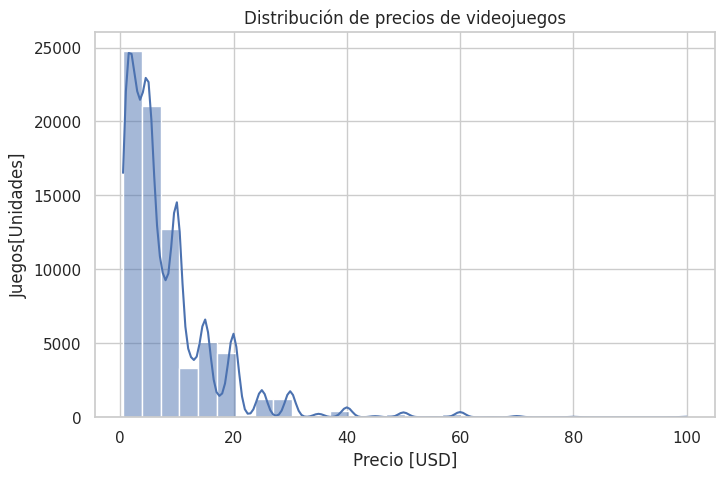

In [ ]:
# Graficamos la distribución de la variable objetivo price
plt.figure(figsize=(8, 5))

# Usamos df_modelo y minúscula en 'price' según nuestro DataFrame actual
sns.histplot(data=df_modelo, x="price", bins=30, kde=True)

plt.title("Distribución de precios de videojuegos")
plt.xlabel("Precio [USD]")
plt.ylabel("Juegos[Unidades]")

plt.show()


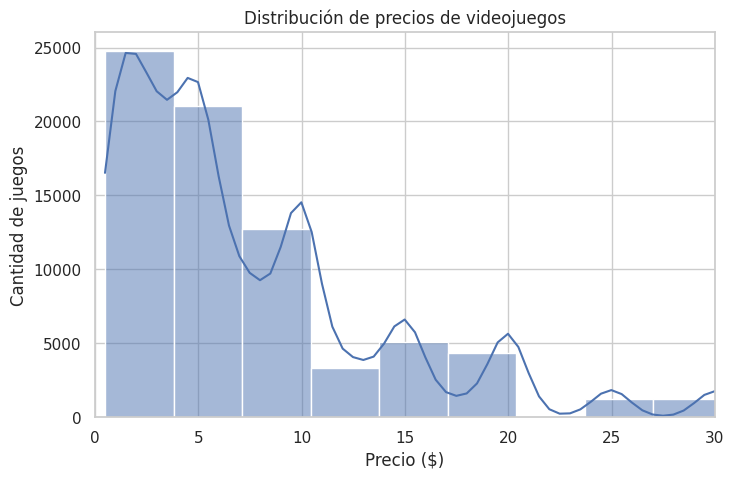

In [ ]:
# Graficamos la distribución de la variable objetivo price limitando el eje X
plt.figure(figsize=(8, 5))

sns.histplot(data=df_modelo, x="price", bins=30, kde=True)

# Limitamos el eje X para recortar los valores extremos y ver bien el grueso de los datos
plt.xlim(0, 30)

plt.title("Distribución de precios de videojuegos")
plt.xlabel("Precio ($)")
plt.ylabel("Cantidad de juegos")

plt.show()

### Interpretación de la distribución de precios

La mayoría de los videojuegos del dataset se concentra en un rango de precios bajo e intermedio, aproximadamente entre 0 y 20 USD, con una fuerte concentración de títulos económicos y gratuitos (*free-to-play*) en los primeros tramos.

También se observan algunos valores más altos distribuidos hacia la derecha, que podrían corresponder a ediciones coleccionistas, paquetes de franquicias o lanzamientos de gran escala comercial (*AAA*). Por ahora no los eliminaremos automáticamente, ya que pueden ser casos reales y útiles para que el futuro modelo aprenda a diferenciar entre distintos segmentos y escalas de precios en el mercado.

Esta observación será importante más adelante, cuando se evalúe el rendimiento de un modelo de regresión.

### Relación entre complejidad de contenido y precio

Una de las variables técnicas que puede influir en el precio de un videojuego es el volumen de contenido adicional o la profundidad de diseño, medida a través de la cantidad de logros (`achievements`) o el número de contenidos descargables (`dlc_count`).

A continuación vamos a observar la relación entre estas variables y el precio (`price`). Esta visualización no demuestra causalidad, pero puede ayudarnos a detectar si existe una tendencia general entre la escala del producto y su valor en el mercado.

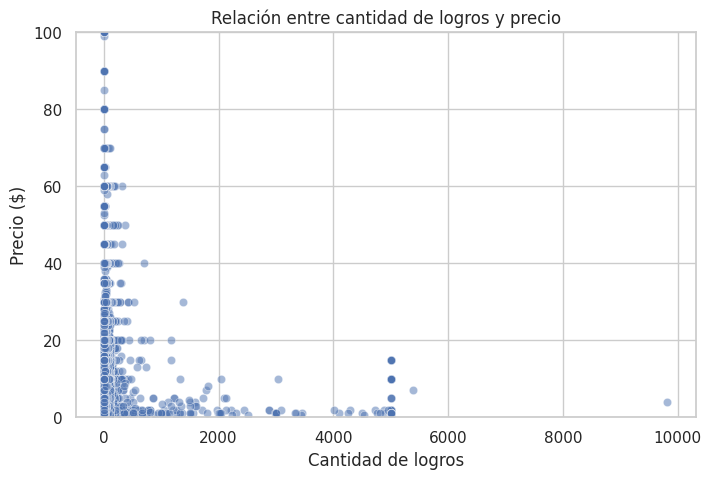

In [ ]:
# Graficamos la relación entre logros y precio
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df_modelo, x="achievements", y="price", alpha=0.5)

plt.title("Relación entre cantidad de logros y precio")
plt.xlabel("Cantidad de logros")
plt.ylabel("Precio ($)")
plt.ylim(0, 100) # Limitamos el eje Y para una mejor visualización

plt.show()


La visualización de los datos mediante un diagrama de dispersión permite evaluar si existe una relación entre la complejidad o profundidad de contenido de un videojuego medida a través de su cantidad de logros (`achievements`) y su valor comercial en el mercado (`price`).

Del análisis del gráfico se deduce que no existe una correlación lineal positiva directa entre ambas variables. Mientras que los juegos con precios elevados se distribuyen principalmente en niveles bajos de logros, aquellos títulos que registran una cantidad extrema de logros (superando los 4,000 y alcanzando picos cercanos a 10,000) se concentran sistemáticamente en los rangos de precios más económicos. Esto demuestra que la cantidad de logros por sí sola no actúa como un factor determinante o inflacionario en el precio final del software.

### Análisis de la relación entre puntaje de Metacritic y precio

El diagrama de dispersión permite evaluar la asociación entre la calidad percibida por la crítica especializada (`metacritic_score`) y el precio de venta del software (`price`).

Del análisis visual se desprende que no existe una correlación lineal directa y estricta entre ambas variables. Si bien los títulos con precios más elevados ($60 USD o más) se concentran en puntajes superiores a 60, la dispersión general demuestra que un puntaje alto en Metacritic no determina de forma exclusiva un mayor costo en el mercado, conviviendo producciones bien valoradas en diversos rangos económicos.

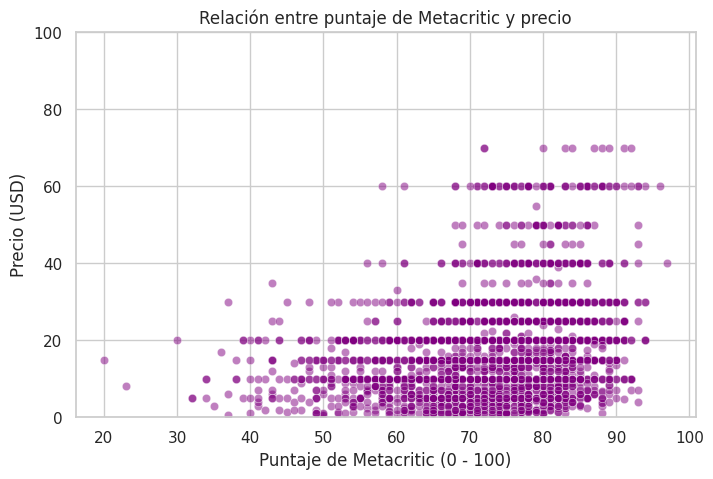

In [ ]:
# Graficamos la relación entre la puntuación de Metacritic y el precio
plt.figure(figsize=(8, 5))

# Usamos df_modelo para graficar las variables ya limpias
sns.scatterplot(data=df_modelo, x="metacritic_score", y="price", alpha=0.5, color="purple")

plt.title("Relación entre puntaje de Metacritic y precio")
plt.xlabel("Puntaje de Metacritic (0 - 100)")
plt.ylabel("Precio (USD)")

# Como ya filtramos los precios máximos a 100, el eje Y se ajustará bien,
# pero podemos fijarlo por seguridad entre 0 y 100
plt.ylim(0, 100)

plt.show()

### Análisis de la relación entre antigüedad del producto y precio

El gráfico de dispersión permite evaluar el impacto del ciclo de vida comercial a través de los años transcurridos desde el lanzamiento del videojuego en relación con su precio actual (`price`)

Del análisis visual se observa una tendencia clara de depreciación: mientras que los juegos más recientes concentran todo el espectro de precios (incluyendo los valores más elevados de hasta $100 USD), los títulos con mayor antigüedad (más de 15 años en el mercado) reducen drásticamente su costo máximo, concentrándose de forma sistemática en los tramos más económicos de la plataforma

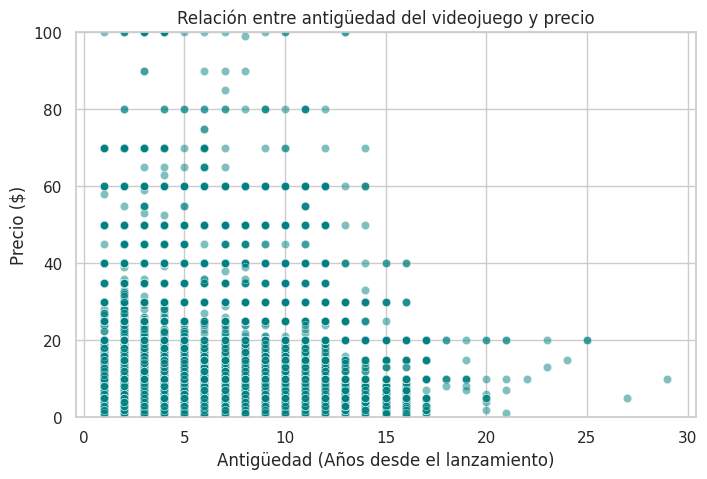

In [ ]:
#1. Convertimos release_date a formato fecha y extraemos el año
df_modelo['release_year'] = pd.to_datetime(df_modelo['release_date'], errors='coerce').dt.year

# 2. Calculamos los años de antigüedad (tomando como referencia el año actual o 2026)
df_modelo['antiguedad_anios'] = 2026 - df_modelo['release_year']

# 3. Graficamos la relación entre antigüedad y precio
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_modelo, x="antiguedad_anios", y="price", alpha=0.5, color="teal")

plt.title("Relación entre antigüedad del videojuego y precio")
plt.xlabel("Antigüedad (Años desde el lanzamiento)")
plt.ylabel("Precio ($)")
plt.ylim(0, 100)
plt.show()

### Análisis de la relación entre base de usuarios estimados y precio

El gráfico de dispersión permite evaluar el vínculo entre la magnitud de la base de propietarios estimados (`estimated_owners`) y el precio de comercialización del videojuego (`price`).

Del análisis visual se deduce que la adopción masiva de usuarios no presenta una relación lineal directa con un costo elevado. Si bien los productos con precios altos se extienden a lo largo de varias categorías de adopción, la gran masa de títulos se concentra en los segmentos de menor a moderada escala comercial, demostrando que el éxito en la tracción de usuarios no está determinado de forma exclusiva por la estrategia de precios inicial.

/tmp/ipykernel_807/4066394096.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_modelo, x="estimated_owners", y="price", palette="Set2")


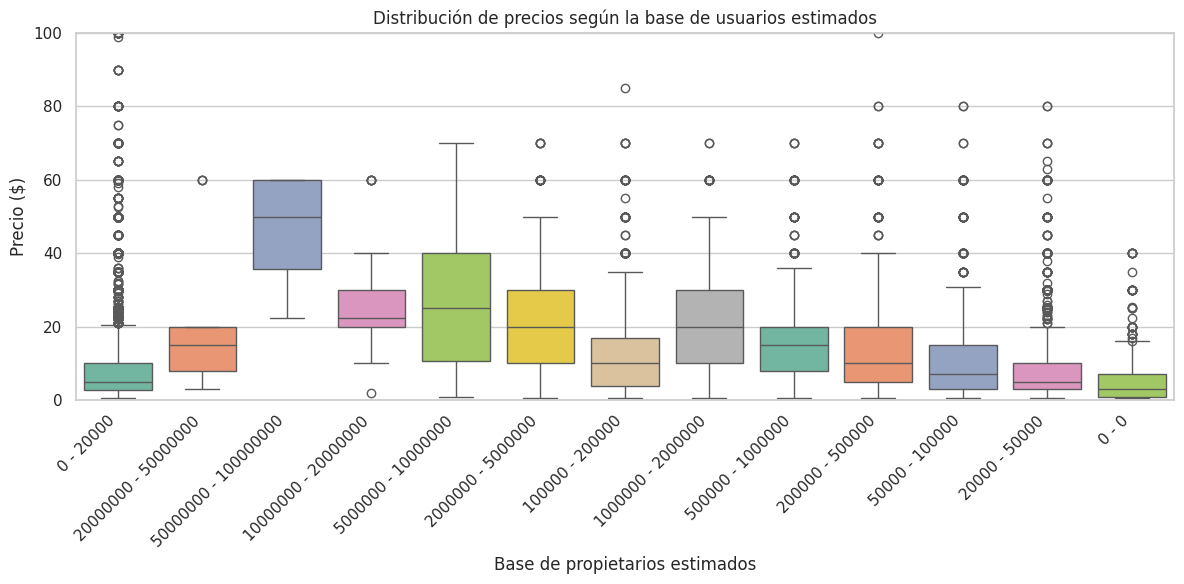

In [ ]:


# 1. Definimos el tamaño de la figura
plt.figure(figsize=(12, 6))

# 2. Generamos un boxplot para ver la distribución de precios según los rangos de usuarios estimados
sns.boxplot(data=df_modelo, x="estimated_owners", y="price", palette="Set2")

plt.title("Distribución de precios según la base de usuarios estimados")
plt.xlabel("Base de propietarios estimados")
plt.ylabel("Precio ($)")

# Limitamos el eje Y para que los valores extremos no aplasten la visualización de las cajas
plt.ylim(0, 100)

# Rotamos las etiquetas del eje X para que no se superpongan
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Análisis de la relación entre la crítica especializada y la adopción comercial
El análisis mediante diagramas de caja (*boxplot*) de la distribución del puntaje de Metacritic según los rangos de propietarios estimados (`estimated_owners`) revela un patrón estructural clave en la industria del videojuego:

Se observa una marcada tendencia donde los títulos ubicados en los tramos de mayor volumen de ventas (extremo izquierdo) concentran las medianas de calificación más elevadas (superiores a 85 puntos). Este fenómeno evidencia un sesgo de cobertura por parte de la crítica especializada, la cual tiende a focalizar sus evaluaciones y otorgar puntajes altos preferentemente a los grandes lanzamientos comerciales (*AAA*). En contraparte, los segmentos de menor adopción presentan una mayor dispersión y medianas de calificación más moderadas, ratificando que la cobertura de la prensa tradicional no posee una distribución uniforme a lo largo de todo el espectro de desarrollos independientes.

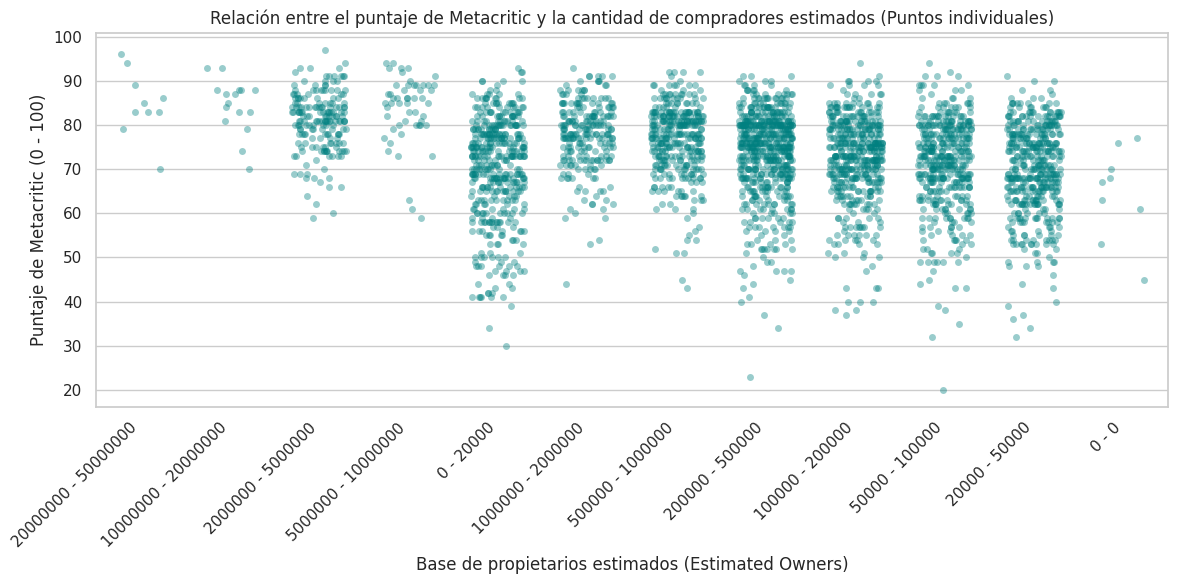

In [ ]:
# Graficamos la relación entre el puntaje de Metacritic y la base de usuarios estimados mostrando los puntos
plt.figure(figsize=(12, 6))

# Filtramos previamente para trabajar solo con los juegos que sí tienen puntaje de Metacritic válido
df_temp = df_modelo[df_modelo['metacritic_score'].notnull()].copy()

# Usamos stripplot para ver los puntos individuales con un pequeño desplazamiento aleatorio (jitter) para que no se superpongan
sns.stripplot(data=df_temp, x="estimated_owners", y="metacritic_score", color="teal", alpha=0.4, jitter=0.3, size=5)

plt.title("Relación entre el puntaje de Metacritic y la cantidad de compradores estimados (Puntos individuales)")
plt.xlabel("Base de propietarios estimados (Estimated Owners)")
plt.ylabel("Puntaje de Metacritic (0 - 100)")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Análisis de la distribución del puntaje de Metacritic según los géneros principales

El diagrama de caja (*boxplot*) permite comparar la distribución de las calificaciones otorgadas por la crítica especializada (`metacritic_score`) en función de los principales géneros de la industria del videojuego.

Del análisis visual de las medianas y la dispersión se desprenden las siguientes observaciones clave:
* **Uniformidad en las valoraciones centrales:** Las medianas de puntaje para la gran mayoría de los géneros troncales (tales como *Action*, *Adventure*, *RPG*, *Strategy* y *Simulation*) se ubican en un rango muy homogéneo, oscilando consistentemente alrededor de los 73 a 76 puntos. Esto indica que la crítica especializada mantiene criterios de evaluación equilibrados y estables en los segmentos comerciales masivos.
* **Dispersión y valores atípicos:** Se observa que géneros amplios como *Action* y *Adventure* concentran una mayor densidad de valores atípicos inferiores (puntos por debajo de los 50 puntos), lo que responde al volumen masivo de títulos lanzados en estas categorías, donde coexisten producciones de alto presupuesto con desarrollos de menor calidad.
* **Implicancia para el modelado:** La similitud en las distribuciones de calificación entre distintos géneros demuestra que la categoría temática por sí sola no genera una diferenciación drástica en la nota crítica, ratificando la necesidad de combinar esta variable con otras características estructurales para predecir con precisión el comportamiento comercial y de precios del software.

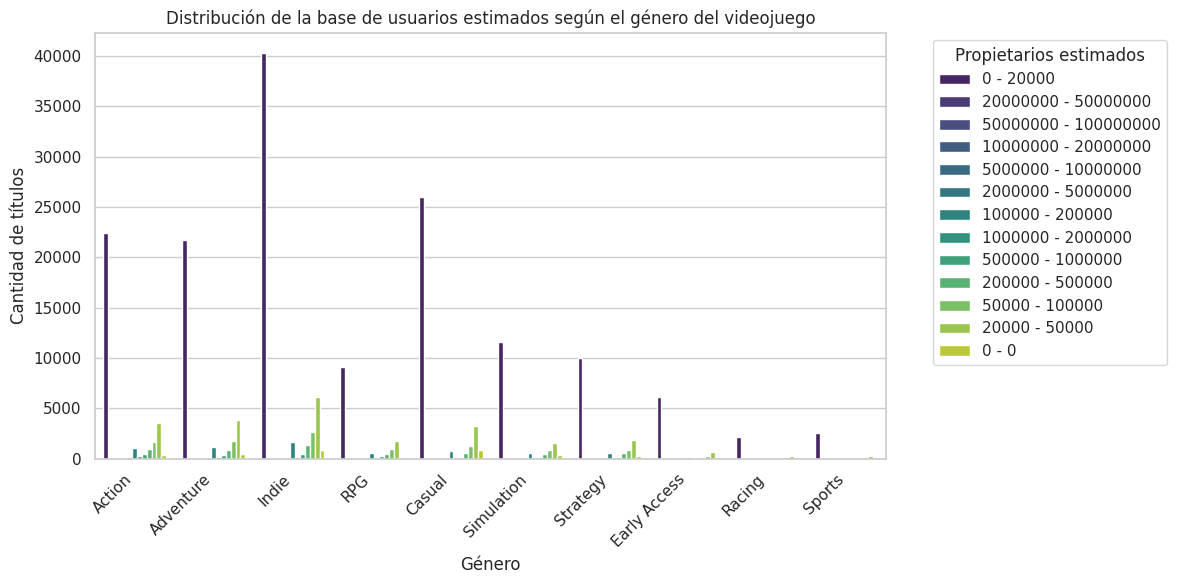

In [ ]:
# 1. Limpiamos y separamos los géneros correctamente eliminando corchetes, comillas y espacios
df_gen_owners = df_modelo.copy()
df_gen_owners['genres'] = (
    df_gen_owners['genres']
    .astype(str)
    .str.replace(r"[\[\]'']", "", regex=True) # Saca corchetes y comillas sueltas
    .str.split(',')
)
df_gen_owners = df_gen_owners.explode('genres')
df_gen_owners['genres'] = df_gen_owners['genres'].str.strip()

# 2. Nos quedamos solo con los géneros limpios más frecuentes (evitando duplicados)
top_gen = df_gen_owners['genres'].value_counts().head(10).index
df_gen_owners_top = df_gen_owners[df_gen_owners['genres'].isin(top_gen)]

# 3. Graficamos de manera limpia y ordenada
plt.figure(figsize=(12, 6))
sns.countplot(data=df_gen_owners_top, x="genres", hue="estimated_owners", palette="viridis")

plt.title("Distribución de la base de usuarios estimados según el género del videojuego")
plt.xlabel("Género")
plt.ylabel("Cantidad de títulos")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Propietarios estimados", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

/tmp/ipykernel_807/1430802792.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_gen_meta_filtrado, x="genres", y="metacritic_score", palette="Spectral")


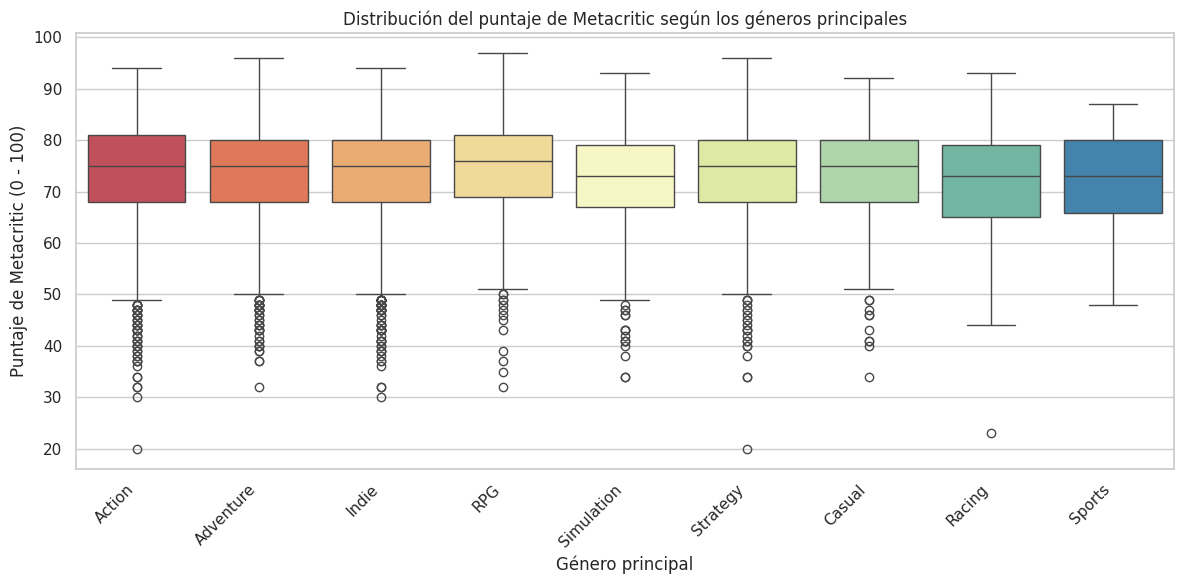

In [ ]:
# 1. Filtramos los juegos que tienen puntaje válido de Metacritic
df_gen_meta = df_modelo[df_modelo['metacritic_score'].notnull()].copy()

# 2. Limpiamos los textos eliminando corchetes, comillas y espacios para evitar duplicados
df_gen_meta['genres'] = (
    df_gen_meta['genres']
    .astype(str)
    .str.replace(r"[\[\]'']", "", regex=True) # Saca corchetes y comillas sueltas
    .str.split(',')
)
df_gen_meta = df_gen_meta.explode('genres')
df_gen_meta['genres'] = df_gen_meta['genres'].str.strip()

# 3. Definimos explícitamente una lista con los géneros más relevantes y comerciales del mercado
generos_relevantes = ['Action', 'Adventure', 'RPG', 'Strategy', 'Simulation', 'Indie', 'Casual', 'Sports', 'Racing']

# Filtramos el DataFrame para quedarnos solo con estos géneros limpios y sin repeticiones
df_gen_meta_filtrado = df_gen_meta[df_gen_meta['genres'].isin(generos_relevantes)]

# 4. Graficamos el boxplot de manera limpia y ordenada
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_gen_meta_filtrado, x="genres", y="metacritic_score", palette="Spectral")

plt.title("Distribución del puntaje de Metacritic según los géneros principales")
plt.xlabel("Género principal")
plt.ylabel("Puntaje de Metacritic (0 - 100)")
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

### Análisis Riguroso de la Matriz de Correlación

La evaluación cuantitativa de las asociaciones lineales mediante el coeficiente de correlación de Pearson sobre el conjunto de datos optimizado permite establecer consideraciones estadísticas fundamentales de cara al diseño del modelo predictivo:

1. **Baja Colinealidad y Ausencia de Relaciones Lineales Fuertes:**
   La matriz de correlación evidencia que ninguna de las variables cuantitativas analizadas (incluyendo la restricción etaria, la cantidad de contenidos descargables, el volumen de logros y la estimación numérica de usuarios) posee una relación lineal fuerte con la variable objetivo (`price`). Los coeficientes de correlación se sitúan en un rango de muy baja intensidad, oscilando entre valores cercanos a cero y un máximo absoluto de `0.26`. Esto demuestra estadísticamente que el precio de un videojuego en la plataforma Steam no responde a una función lineal simple de una única característica técnica o comercial.

2. **Asociación Máxima y su Significado Estadístico:**
   El coeficiente más elevado se registra entre el precio (`price`) y la puntuación de la crítica especializada (`metacritic_score`), alcanzando un valor de `0.26. Desde una perspectiva estadística, un coeficiente de esta magnitud denota una correlación positiva débil. Si bien indica una ligera tendencia a que los productos mejor valorados por la prensa presenten costos de mercado superiores, su valor numérico es insuficiente para construir un modelo predictivo univariado robusto, ratificando la necesidad de incorporar interacciones multivariadas.

3. **Ortogonalidad e Independencia entre Características Predictoras:**
   Entre las variables predictoras independientes (excluyendo el objetivo), las correlaciones son prácticamente nulas (por ejemplo, `0.01` entre logros y precio, o `0.02` entre logros y usuarios estimados). Desde el punto de vista del Machine Learning, esta baja colinealidad entre las *features* es una propiedad altamente deseable, ya que significa que las variables seleccionadas no sufren de redundancia informativa severa ni multicolinealidad colosal, aportando cada una dimensiones ortogonales u opiniones independientes sobre el producto.

4. **Implicancias Metodológicas para el Modelado:**
   El hecho de que las correlaciones lineales sean globalmente débiles confirma que el comportamiento del mercado de videojuegos está gobernado por patrones no lineales, segmentaciones categóricas (como géneros, desarrolladores y editoriales) y relaciones complejas. En consecuencia, se justifica rigurosamente la transición desde modelos lineales simples hacia algoritmos de Machine Learning de mayor complejidad y flexibilidad (tales como árboles de decisión, ensamblados o modelos basados en particiones) capaces de capturar interacciones no lineales que escapan al análisis de correlación bivariada de Pearson.

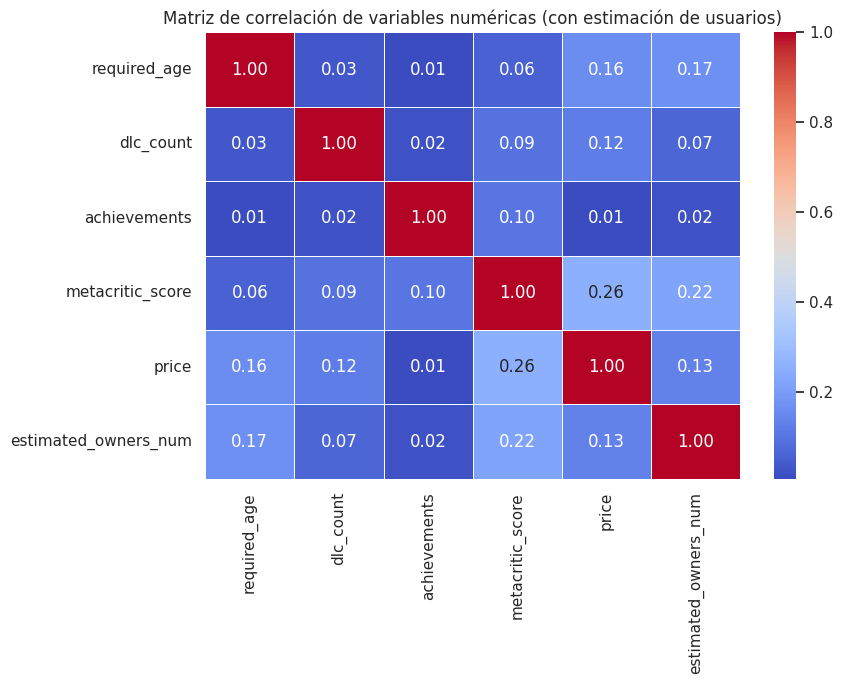

In [ ]:
# 1. Creamos una copia temporal para no alterar el original y transformamos 'estimated_owners' en numérico
df_corr_temp = df_modelo.copy()

if 'estimated_owners' in df_corr_temp.columns and df_corr_temp['estimated_owners'].dtype == 'object':
    # Extraemos el primer número del rango de texto (ej: "100000 - 200000" extrae "100000")
    df_corr_temp['estimated_owners_num'] = (
        df_corr_temp['estimated_owners']
        .astype(str)
        .str.split('-')
        .str[0]
        .str.replace(r'\D', '', regex=True) # Elimina comas, espacios o caracteres no numéricos
    )
    # Convertimos a tipo numérico (float/int)
    df_corr_temp['estimated_owners_num'] = pd.to_numeric(df_corr_temp['estimated_owners_num'], errors='coerce')

# 2. Seleccionamos todas las columnas numéricas (incluyendo la nueva y las anteriores)
columnas_numericas = df_corr_temp.select_dtypes(include=['float64', 'int64'])

# 3. Calculamos la matriz de correlación
matriz_corr = columnas_numericas.corr()

# 4. Graficamos la matriz usando un mapa de calor (heatmap)
plt.figure(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title("Matriz de correlación de variables numéricas (con estimación de usuarios)")
plt.tight_layout()
plt.show()

## Transformaciones básicas

Antes de entrenar un modelo de Machine Learning, los datos deben estar en un formato adecuado para su procesamiento matemático.

En general, los modelos predictivos no trabajan directamente con texto libre o variables categóricas no estructuradas. Por esta razón, atributos clave como los géneros (`genres`), los estudios desarrolladores (`developers`) y las empresas editoras (`publishers`) requerirán procesos de transformación a valores numéricos en fases posteriores. Asimismo, las variables cuantitativas (tales como la cantidad de logros, la antigüedad o el puntaje de la crítica) podrán requerir técnicas de escalado, especialmente si se implementan algoritmos sensibles a la magnitud de las escalas numéricas.

En esta etapa vamos a identificar formalmente qué columnas conservadas en nuestro subconjunto de trabajo (`df_modelo`) son numéricas y cuáles son categóricas, estableciendo la base para la codificación y preparación final de los datos.

In [ ]:
# Identificamos columnas numéricas en nuestro DataFrame optimizado
columnas_numericas = df_modelo.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()

# Identificamos columnas categóricas / de texto en nuestro DataFrame optimizado
columnas_categoricas = df_modelo.select_dtypes(include=["object", "category"]).columns.tolist()

print("Columnas numéricas seleccionadas para el modelo:")
for col in columnas_numericas:
    print(f" - {col}")

print("\nColumnas categóricas seleccionadas para el modelo:")
for col in columnas_categoricas:
    print(f" - {col}")

Columnas numéricas seleccionadas para el modelo:
 - required_age
 - dlc_count
 - achievements
 - metacritic_score
 - price
 - release_year
 - antiguedad_anios

Columnas categóricas seleccionadas para el modelo:
 - name
 - release_date
 - developers
 - publishers
 - genres
 - estimated_owners


### Separación de variable objetivo y variables predictoras

En este conjunto de datos, la variable objetivo es `price`, debido a que representa el valor monetario de adquisición que más adelante se intentará predecir mediante un modelo de regresión.

El resto de las columnas conservadas en nuestro subconjunto de trabajo funcionarán como variables predictoras (*features*), es decir, como las características estructurales, técnicas y de reputación que ayudarán al algoritmo a estimar con precisión el precio del software.

Antes de aplicar transformaciones posteriores, vamos a separar formalmente:
* **`X`**: Conjunto de variables predictoras.
* **`y`**: Variable objetivo (`price`).

In [ ]:
# Separamos la variable objetivo
y = df_modelo["price"]

# Separamos las variables predictoras (excluyendo 'price' y el identificador 'name')
X = df_modelo.drop(columns=["price", "name"], errors='ignore')

# Verificamos las dimensiones
print("Dimensiones de X (Variables predictoras):")
print(X.shape)

print("\nDimensiones de y (Variable objetivo):")
print(y.shape)

Dimensiones de X (Variables predictoras):
(75094, 14)

Dimensiones de y (Variable objetivo):
(75094,)


## Identificación de columnas predictoras numéricas y categóricas

Ahora que hemos separado la variable objetivo (`price`), vamos a identificar formalmente las columnas numéricas y categóricas dentro del conjunto de variables predictoras (`X`).

Esta distinción es fundamental porque las etapas posteriores de transformación se aplican de manera diferenciada según la naturaleza de cada atributo:
* **Variables numéricas:** Podrán ser sometidas a procesos de escalado o normalización si el algoritmo seleccionado lo requiere.
* **Variables categóricas:** Deberán ser codificadas mediante técnicas de transformación (como One-Hot Encoding o Label Encoding) para convertirse en valores numéricos aptos para los cálculos matemáticos del modelo.

In [ ]:
# Identificamos columnas numéricas dentro de X (incluyendo enteros y flotantes)
columnas_numericas = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()

# Identificamos columnas categóricas dentro de X (incluyendo texto y objetos)
columnas_categoricas = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Columnas numéricas predictoras:")
for col in columnas_numericas:
    print(f" - {col}")

print("\nColumnas categóricas predictoras:")
for col in columnas_categoricas:
    print(f" - {col}")

Columnas numéricas predictoras:
 - required_age
 - dlc_count
 - achievements
 - metacritic_score
 - release_year
 - antiguedad_anios

Columnas categóricas predictoras:
 - release_date
 - developers
 - publishers
 - genres
 - estimated_owners


## Revisión de variables categóricas

Las variables categóricas contienen texto o etiquetas descriptivas, tales como el estudio desarrollador, la empresa editora o los géneros del videojuego.

Antes de proceder a codificarlas, es fundamental revisar cuántos valores distintos (*cardinalidad*) posee cada una. Si una columna cuenta con una cantidad excesiva de categorías diferentes, su transformación posterior (por ejemplo, mediante codificación *One-Hot*) podría expandir artificialmente la dimensionalidad del dataset, volviéndolo ineficiente para el modelo.

En esta celda vamos a contar la cantidad de valores únicos de cada variable categórica presente en el conjunto de predictoras.

In [ ]:
# Contamos la cantidad de valores únicos en cada columna categórica de X
for columna in columnas_categoricas:
    print(f"{columna}: {X[columna].nunique()} valores únicos")

release_date: 4398 valores únicos
developers: 46962 valores únicos
publishers: 41096 valores únicos
genres: 1576 valores únicos
estimated_owners: 13 valores únicos


### Observación sobre las variables categóricas

Al revisar las variables categóricas, vemos que no todas tienen el mismo nivel de complejidad ni el mismo grado de cardinalidad.

Algunas columnas tienen pocos valores únicos, como `estimated_owners` (con solo 13 categorías). Estas variables son manejables y directas de transformar mediante codificación.

Otras columnas, en cambio, presentan una altísima cardinalidad, tales como los estudios desarrolladores (`developers` con 46,962 valores), las empresas editoras (`publishers` con 41,096 valores), las fechas de lanzamiento (`release_date` con 4,398 valores) y los géneros (`genres` con 1,576 valores). Esto significa que, al intentar codificarlas de manera directa (por ejemplo, mediante *One-Hot Encoding*), el dataset final se expandiría artificialmente en decenas de miles de columnas nuevas, volviéndose computacionalmente inviable.

Por este motivo, antes de aplicar transformaciones definitivas, vamos a seleccionar un conjunto de variables predictoras relevantes, acotadas y manejables para continuar con la preparación del dataset.

## Selección preliminar de variables

Para preparar el dataset para un futuro modelo, no siempre conviene utilizar la totalidad de las columnas disponibles de manera directa.

En este ejemplo vamos a realizar una **selección preliminar** de variables pensando principalmente en:
* Que representen características estructurales, técnicas y comerciales interpretables del videojuego;
* Que sean relativamente simples de transformar y utilizar;
* Que permitan construir un conjunto de datos manejable para esta primera experiencia de modelado.

Algunas columnas, como los estudios desarrolladores (`developers`), las empresas editoras (`publishers`) y los géneros (`genres`), contienen información altamente específica y registran decenas de miles de valores distintos. Codificarlas mediante técnicas masivas produciría una expansión desproporcionada de columnas nuevas. Más adelante podrían analizarse mediante técnicas de reducción de dimensionalidad o codificación avanzada, pero para esta preentrega trabajaremos con un conjunto más acotado y general.

Esta no pretende ser una selección automática ni definitiva de las mejores variables para predecir el precio (`price`). Una selección formal basada rigurosamente en su capacidad predictiva deberá realizarse utilizando únicamente los datos de entrenamiento (*train*), evitando de este modo la filtración de información (*data leakage*) proveniente del conjunto de prueba (*test*) en las decisiones de modelado.

In [ ]:
# Seleccionamos un conjunto de variables predictoras relevantes y manejables
columnas_seleccionadas = [
    'required_age',      # Restricción de edad
    'dlc_count',         # Cantidad de contenidos descargables
    'achievements',      # Complejidad y cantidad de logros
    'windows',           # Soporte para Windows
    'mac',               # Soporte para Mac
    'linux',             # Soporte para Linux
    'metacritic_score',  # Puntuación de la crítica especializada
    'estimated_owners'   # Magnitud de la base de usuarios
]

# Creamos una nueva versión de X con las columnas seleccionadas a partir del DataFrame optimizado
X = df_modelo[columnas_seleccionadas].copy()

# Separamos nuevamente la variable objetivo 'y' asegurando que coincida
y = df_modelo['price']

# Mostramos las primeras filas del nuevo conjunto de variables predictoras
X.head()

,required_age,dlc_count,achievements,windows,mac,linux,metacritic_score,estimated_owners
4,17,9,0,True,False,False,NaN,0 - 20000
5,17,9,0,True,False,False,NaN,0 - 20000
6,17,9,0,True,False,False,NaN,0 - 20000
7,17,9,0,True,False,False,NaN,0 - 20000
8,17,9,0,True,False,False,NaN,20000000 - 50000000


## Revisión de columnas luego de la selección

Después de seleccionar las variables predictoras que vamos a utilizar en nuestro subconjunto optimizado, volvemos a identificar formalmente cuáles son numéricas y cuáles son categóricas.

Esta verificación es necesaria porque las transformaciones posteriores se aplicarán de manera diferenciada según el tipo de dato:
* **Las columnas numéricas** (tales como la restricción de edad, los logros o las puntuaciones) podrán ser sometidas a procesos de escalado.
* **Las columnas categóricas** (tales como los rangos de propietarios estimados) deberán ser codificadas para transformar sus etiquetas en representaciones numéricas aptas para el modelo.

In [ ]:
# Volvemos a identificar columnas numéricas y categóricas luego de la selección
columnas_numericas = X.select_dtypes(include=["int64", "float64", "int32", "float32", "bool"]).columns.tolist()
columnas_categoricas = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Columnas numéricas seleccionadas:")
for col in columnas_numericas:
    print(f" - {col}")

print("\nColumnas categóricas seleccionadas:")
for col in columnas_categoricas:
    print(f" - {col}")

Columnas numéricas seleccionadas:
 - required_age
 - dlc_count
 - achievements
 - windows
 - mac
 - linux
 - metacritic_score

Columnas categóricas seleccionadas:
 - estimated_owners


## Definición de transformaciones básicas

Para que los datos puedan ser utilizados por un modelo de Machine Learning, necesitamos transformar las variables predictoras.

En este caso aplicaremos dos transformaciones principales:
* A las variables numéricas (tales como la restricción de edad, la cantidad de logros, las puntuaciones y las banderas de soporte binario) les aplicaremos un escalado con `StandardScaler`.
* A las variables categóricas (tales como los rangos de propietarios estimados) les aplicaremos codificación con `OneHotEncoder`.

El escalado permite que las variables numéricas queden en una escala comparable, evitando que atributos con magnitudes mayores dominen el aprendizaje del modelo. La codificación convierte categorías de texto en columnas numéricas binarias que un algoritmo de Machine Learning puede interpretar adecuadamente.

Por buena práctica metodológica, definiremos estas transformaciones en este momento, pero **las aplicaremos exclusivamente después de dividir el dataset en entrenamiento y prueba**, evitando así cualquier filtración de información (*data leakage*).

In [ ]:
# Importamos las herramientas de Scikit-Learn para transformar los datos de forma integrada
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Definimos el preprocesamiento para columnas numéricas y categóricas utilizando las listas identificadas
preprocesamiento = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), columnas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas)
    ],
    remainder="passthrough" # Asegura que si queda alguna columna sin especificar, se mantenga intacta
)

# Visualizamos el objeto transformador ColumnTransformer configurado
preprocesamiento

ColumnTransformer(remainder='passthrough',
                  transformers=[('num', StandardScaler(),
                                 ['required_age', 'dlc_count', 'achievements',
                                  'windows', 'mac', 'linux',
                                  'metacritic_score']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['estimated_owners'])])

## División en entrenamiento y prueba

Antes de entrenar un modelo, necesitamos separar los datos en dos conjuntos independientes:
* Un conjunto de **entrenamiento**, que el modelo utilizará para aprender los patrones subyacentes.
* Un conjunto de **prueba**, que servirá para evaluar su rendimiento de manera objetiva sobre datos no vistos.

Usaremos un 80% de los datos para entrenamiento y un 20% para prueba.

Un principio metodológico fundamental es que cualquier transformación que **aprenda parámetros a partir de los datos** (como la imputación de valores faltantes, el escalado de variables numéricas o la codificación de categóricas) debe ajustarse **solamente utilizando el conjunto de entrenamiento**, evitando así cualquier filtración de información (*data leakage*) hacia el conjunto de prueba.

Por este motivo, realizaremos primero la división `train/test` y posteriormente aplicaremos las transformaciones correspondientes de forma aislada en cada subconjunto.

In [ ]:
# Importamos la función para dividir el dataset de manera estratificada/aleatoria
from sklearn.model_selection import train_test_split

# X e y ya fueron definidos anteriormente conteniendo únicamente las variables seleccionadas.

# Dividimos los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ----------------------------------------------------------
# CONTROL DE VALORES FALTANTES Y VALIDACIÓN DE CONJUNTO
# ----------------------------------------------------------

# Verificamos los valores nulos en metacritic_score o variables seleccionadas (si aplican)
print("Valores faltantes en metacritic_score (X_train):", X_train["metacritic_score"].isna().sum())
print("Valores faltantes en metacritic_score (X_test) :", X_test["metacritic_score"].isna().sum())

# Verificamos las dimensiones de los conjuntos resultantes
print("\nDimensiones de X_train:", X_train.shape)
print("Dimensiones de X_test:", X_test.shape)
print("Dimensiones de y_train:", y_train.shape)
print("Dimensiones de y_test:", y_test.shape)

Valores faltantes en metacritic_score (X_train): 57415
Valores faltantes en metacritic_score (X_test) : 14341

Dimensiones de X_train: (60075, 8)
Dimensiones de X_test: (15019, 8)
Dimensiones de y_train: (60075,)
Dimensiones de y_test: (15019,)


## Aplicación del preprocesamiento

Ahora vamos a aplicar las transformaciones definidas previamente sobre nuestros conjuntos de datos.

Usaremos:
* `fit_transform()` sobre `X_train`, para que el preprocesamiento aprenda sus parámetros (medias, desviaciones estándar y categorías) **únicamente a partir de los datos de entrenamiento**;
* `transform()` sobre `X_test`, para aplicar exactamente esas mismas transformaciones aprendidas al conjunto de prueba.

En este caso, el preprocesamiento incluye:
* `StandardScaler` para las variables numéricas;
* `OneHotEncoder` para las variables categóricas.

Esto evita de forma estricta que la información del conjunto de prueba influya o contamine la preparación de los datos (*data leakage*), garantizando una evaluación objetiva y rigurosa del modelo.

In [ ]:
# Aplicamos el preprocesamiento al conjunto de entrenamiento (ajusta parámetros y transforma)
X_train_preparado = preprocesamiento.fit_transform(X_train)

# Aplicamos el mismo preprocesamiento al conjunto de prueba (solo transforma usando lo aprendido en train)
X_test_preparado = preprocesamiento.transform(X_test)

# Mostramos las dimensiones resultantes luego del preprocesamiento matricial
print("Dimensiones de X_train_preparado:", X_train_preparado.shape)
print("Dimensiones de X_test_preparado:", X_test_preparado.shape)

Dimensiones de X_train_preparado: (60075, 20)
Dimensiones de X_test_preparado: (15019, 20)


## Resultado del preprocesamiento

Después de aplicar el preprocesamiento, `X_train_preparado` y `X_test_preparado` quedan transformados en matrices numéricas densas listas para ser utilizadas por los algoritmos de Machine Learning.

Las variables numéricas fueron escaladas con `StandardScaler`, mientras que las variables categóricas (como los rangos de propietarios estimados) fueron convertidas mediante `OneHotEncoder` en múltiples columnas binarias, una por cada categoría aprendida por el codificador.

Por esta razón, el número total de columnas después del preprocesamiento puede diferir del número de variables originales. En este dataset, tras la expansión de las categorías, obtenemos un total de **20 columnas** resultantes (distribuidas en 60,075 observaciones para entrenamiento y 15,019 observaciones para prueba).

Lo más importante a destacar es que las transformaciones fueron **ajustadas estrictamente con `X_train`** y posteriormente aplicadas a `X_test` utilizando los parámetros ya aprendidos. De esta manera, se garantiza que el conjunto de prueba permanezca totalmente independiente y no intervenga en la preparación del modelo.

## Checklist final de la Pre-Entrega

En este cuaderno recorrimos y documentamos todas las etapas principales solicitadas para la Pre-Entrega del Proyecto Integrador:

* Seleccionamos un dataset tabular de la industria de videojuegos (`price` como variable objetivo);
* Describimos y contextualizamos el problema comercial y de regresión abordado;
* Realizamos un análisis exploratorio inicial (EDA) con distribuciones y visualizaciones gráficas;
* Revisamos valores faltantes, anomalías y códigos centinela (como el tratamiento del `-1` en edad y de los ceros en Metacritic);
* Justificamos metodológicamente cada decisión de limpieza, filtrado de juegos gratuitos (*Free-to-Play*) y acotación de valores atípicos;
* Identificamos formalmente variables numéricas y categóricas;
* Realizamos una selección preliminar y acotada de variables predictoras para evitar la alta cardinalidad;
* Dividimos el dataset en conjuntos independientes de entrenamiento y prueba (80/20);
* Definimos transformaciones con `ColumnTransformer` utilizando `StandardScaler` y `OneHotEncoder`;
* Ajustamos el escalado y la codificación estrictamente con los datos de entrenamiento (`X_train`);
* Aplicamos a `X_test` las transformaciones ya aprendidas, evitando la filtración de información (*data leakage*).

A partir de este punto, los datos quedan estructurados, normalizados y preparados para la siguiente etapa del proyecto: el entrenamiento, optimización y evaluación de modelos predictivos de Machine Learning.

### Para aplicar esta guía a otros proyectos

No es necesario repetir exactamente las mismas decisiones técnicas. Cada conjunto de dominio presenta problemáticas y naturalezas diferentes.

Lo que sí conviene conservar como buena práctica transversal es el criterio general:
1. **Diagnosticar** los datos antes de modificarlos;
2. **Justificar** cada decisión de limpieza o filtrado comercial;
3. Identificar claramente la variable objetivo y las predictoras;
4. Separar entrenamiento y prueba **antes de ajustar transformaciones que aprendan parámetros**;
5. Aprender escalados o codificaciones únicamente con `X_train`;
6. Aplicar a `X_test` exactamente lo aprendido en el entrenamiento sin reajustar.

En la entrega final, esta sólida base de preprocesamiento permitirá probar, ajustar y comparar distintos algoritmos de regresión para estimar con precisión el precio de los videojuegos a partir de sus características estructurales, técnicas y de reputación en el mercado.

### Consideraciones finales sobre la no linealidad de los datos y perspectivas futuras

A partir de los análisis exploratorios realizados incluyendo las distribuciones de variables, los gráficos de dispersión y la matriz de correlación, se evidenció que las características del mercado de videojuegos en la plataforma Steam no responden a patrones de linealidad estricta ni a dependencias bivariadas simples frente al precio (`price`).

Los coeficientes de correlación y la dispersión observada demuestran que la fijación de precios en la industria del software no es confiable ni explicable mediante enfoques puramente lineales. El comportamiento comercial está sujeto a interacciones complejas, multifactoriales y no lineales (asociadas a estrategias de los estudios, recepciones de la comunidad, modelos de monetización y características estructurales cruzadas).

En consecuencia, esta base de datos y la arquitectura de preprocesamiento actual quedan abiertas y sujetas a futuros ajustes. Para las próximas etapas del proyecto, será necesario transicionar hacia la implementación de algoritmos y métodos de Machine Learning avanzados que capturen relaciones no lineales complejas (tales como árboles de decisión, modelos de ensamblaje o redes de partición), permitiendo alcanzar un rendimiento predictivo superior y un análisis de mercado más robusto.